# Facebook Comment Volume Prediction – Keras / TensorFlow (Regression)
**Dataset:** `Features_Variant_1.csv` (UCI Facebook Comment Volume) | **Target:** post par kitne comments aayenge (number)

**Steps:** Data load → EDA (seaborn/matplotlib) → Cleaning → Log transform + Split + Scale → Baseline → Neural Network (3 versions) → Evaluation → Conclusion

> Ye **regression** hai: target ek number hai (0, 5, 300...), koi category nahi. Isliye output layer mein **1 node, koi activation nahi**, loss = `mse`.
>
> Is notebook mein **har code line ke saath Hinglish comment** hai, taaki har line ka matlab samajh aaye.

## 1. Libraries

In [ ]:
import numpy as np                                    # numpy: numbers aur maths ke liye, 'np' short naam se
import pandas as pd                                   # pandas: data ko table (DataFrame) mein rakhne ke liye
import matplotlib.pyplot as plt                       # matplotlib: charts banane ke liye
import seaborn as sns                                 # seaborn: matplotlib ke upar sundar charts ke liye
import tensorflow as tf                               # tensorflow: deep learning ka main engine
from tensorflow import keras                          # keras: tensorflow ke andar model banane ki aasaan library
from tensorflow.keras import layers                   # layers: Dense jaise layers yahin se aate hain
from sklearn.model_selection import train_test_split  # data ko train aur test mein baantne ke liye
from sklearn.preprocessing import StandardScaler      # features ko ek jaise scale par laane ke liye
from sklearn.linear_model import LinearRegression     # baseline ke liye seedhi line wala model
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score  # regression ke scores nikalne ke liye

sns.set_theme(style="whitegrid")                      # seaborn ka saaf-suthra white grid look laga do
np.random.seed(42)                                    # numpy ka random fix karo taaki har baar same result aaye
tf.random.set_seed(42)                                # tensorflow ka random bhi fix karo (reproducibility)

## 2. Data load karo

In [ ]:
df = pd.read_csv("Features_Variant_1.csv", header=None)  # CSV padho; header=None kyunki file mein column names nahi hain
print("Shape:", df.shape)                                # (rows, columns) print karo

In [ ]:
df = pd.read_csv('Features_Variant_1.csv', header=None)


In [ ]:
df.shape

In [ ]:
df.head()

In [ ]:
# UCI ke documentation ke hisaab se columns ko naam de do (padhne mein aasaani)
cols = (["page_likes", "page_checkins", "page_talking_about", "page_category"]   # column 0-3: page ki jaankari
        + [f"derived_{i:02d}" for i in range(1, 26)]                               # column 4-28: 25 derived features (min/max/avg type)
        + ["cc1_total_before", "cc2_last_24h", "cc3_24_48h",                       # column 29-31: pehle ke comments ki ginti
           "cc4_first_24h_after", "cc5_cc2_minus_cc3"]                             # column 32-33: baaki comment features
        + ["base_time_hours", "post_length", "post_share_count",                   # column 34-36: time, post ki lambai, shares
           "promotion_status", "h_local"]                                          # column 37-38: promotion status, local time
        + [f"pub_day_{d}" for d in ["sun", "mon", "tue", "wed", "thu", "fri", "sat"]]   # column 39-45: post kis din publish hui
        + [f"base_day_{d}" for d in ["sun", "mon", "tue", "wed", "thu", "fri", "sat"]]  # column 46-52: base time ka din
        + ["target_comments"])                                                     # column 53: TARGET (comments ki sankhya)
df.columns = cols                                    # ye naam DataFrame ke columns bana do
print("Columns ki sankhya:", len(cols))              # total columns check karo
df.head()                                            # pehli 5 rows dekho

In [ ]:
df.info()                                            # har column ka data type aur non-null count dikhao

In [ ]:
print("Total null values:", df.isnull().sum().sum())     # saare columns ke missing values ka total
print("Duplicate rows   :", df.duplicated().sum())       # kitni rows bilkul ek jaisi hain
df[["page_likes", "cc1_total_before", "post_length", "post_share_count", "target_comments"]].describe()  # kuch columns ka mean/min/max/std

## 3. EDA – target ko samjho

In [ ]:
y_raw = df["target_comments"]                                                  # target column ko alag variable mein rakho
print("Zero comments wale posts: {:.1f}%".format((y_raw == 0).mean() * 100))   # kitne % posts par 0 comments hain
print("Median:", y_raw.median(), "| Mean:", round(y_raw.mean(), 2), "| Max:", y_raw.max())  # median, average aur sabse bada value

fig, ax = plt.subplots(1, 2, figsize=(13, 4))                                  # 1 row, 2 charts wali figure banao
sns.histplot(y_raw.clip(upper=y_raw.quantile(0.99)), bins=50, ax=ax[0])        # 99th percentile tak ka histogram (outliers kaat ke)
ax[0].set_title("Asli target (99th percentile tak)")                           # pehle chart ka title
ax[0].set_xlabel("comments")                                                   # x-axis ka naam
sns.histplot(np.log1p(y_raw), bins=50, ax=ax[1], color="darkorange")           # log1p ke baad ka histogram
ax[1].set_title("log1p(target)  ->  kam skewed")                               # doosre chart ka title
ax[1].set_xlabel("log(1 + comments)")                                          # x-axis ka naam
plt.tight_layout()                                                             # charts ek-doosre par na chadhein
plt.show()                                                                     # charts screen par dikhao

**Observation:** target bahut **skewed** hai. Zyadatar posts par 0-3 comments aate hain aur kuch posts viral ho jaate hain (hazaaron comments).
Isliye neural network ko seedha asli target par train karne ki jagah hum `np.log1p(y)` par train karenge, aur baad mein `np.expm1` se wapas asli scale par laayenge.

In [ ]:
tmp = df.copy()                                                      # asli df ko chhede bina copy par kaam karo
tmp["log_target"] = np.log1p(tmp["target_comments"])                 # target ka log1p nikalo
corr = tmp.drop(columns="target_comments").corr()["log_target"].drop("log_target")   # har feature ka log_target se correlation
top = corr.abs().sort_values(ascending=False).head(12)               # sabse zyada related 12 features chuno
print(corr[top.index].round(3))                                      # unke correlation values print karo

plt.figure(figsize=(9, 7))                                           # chart ka size set karo
sns.heatmap(tmp[list(top.index) + ["log_target"]].corr(),            # top features + target ka correlation matrix
            annot=True, fmt=".2f", cmap="coolwarm", center=0)        # numbers dikhao, 2 decimal, laal-neela rang
plt.title("Top features ka correlation heatmap")                     # chart ka title
plt.show()

## 4. Data Cleaning

In [ ]:
print("Duplicates:", df.duplicated().sum())     # kitni duplicate rows hain
print("Constant columns:", [c for c in df.columns if df[c].nunique() == 1])   # kaun se columns constant hain

## 5. Target transform, Split aur Scaling
- `y = log1p(comments)` (skew kam karne ke liye)
- 80% train, 20% test
- Scaler **train par fit**, test par sirf **transform** (data leakage se bachne ke liye)

In [ ]:
X = df.drop(columns="target_comments").values        # target hata ke baaki sab columns = input features (X)
y = np.log1p(df["target_comments"].values)           # target ka log1p = y (jo model predict karega)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)   # 80% train, 20% test, fixed random

scaler = StandardScaler()                            # scaler object banao
X_train = scaler.fit_transform(X_train)              # train data se mean/std seekho (fit) aur scale karo (transform)
X_test = scaler.transform(X_test)                    # test par sirf transform, wahi train wala mean/std (leakage nahi)

print("Input features ki sankhya:", X_train.shape[1])            # kitne input features hain
print("Train:", X_train.shape, "| Test:", X_test.shape)          # train aur test ka shape

## 6. Baseline models
Neural network ko tabhi "achha" bol sakte hain jab wo simple models se behtar ho.
- **Mean baseline:** hamesha train ka average predict karo (sabse bekaar model)
- **Linear Regression:** seedhi line wala model

In [ ]:
results = []                                                       # saare models ke scores is list mein jama honge

In [ ]:
def evaluate(name, y_true_log, y_pred_log):                        # function: model ka naam, asli aur predicted (log scale) lo
    y_pred_log = np.clip(np.ravel(y_pred_log), 0, None)            # predictions ko 1D karo aur 0 se neeche mat jaane do (comments negative nahi hote)
    rmse_log = np.sqrt(mean_squared_error(y_true_log, y_pred_log)) # log scale par RMSE (bade errors ko zyada saza)
    mae_log = mean_absolute_error(y_true_log, y_pred_log)          # log scale par MAE (average error)
    r2_log = r2_score(y_true_log, y_pred_log)                      # log scale par R2 (1 ke jitna paas, utna behtar)
    y_true = np.expm1(y_true_log)                                  # log se wapas asli comments ki ginti mein badlo
    y_pred = np.expm1(y_pred_log)                                  # predictions ko bhi asli scale par laao
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))             # asli scale par RMSE
    mae = mean_absolute_error(y_true, y_pred)                      # asli scale par MAE (average kitne comments ka galat andaza)
    results.append({"Model": name, "RMSE (log)": rmse_log, "MAE (log)": mae_log, "R2 (log)": r2_log,   # saare scores ek dictionary mein
                    "RMSE (comments)": rmse, "MAE (comments)": mae})                                     # aur list mein daal do
    print(f"{name:22s} | R2(log): {r2_log:6.3f} | RMSE(log): {rmse_log:5.3f} | MAE(comments): {mae:6.2f} | RMSE(comments): {rmse:7.2f}")   # ek line mein result dikhao

In [ ]:
evaluate("Mean Baseline", y_test, np.full_like(y_test, y_train.mean()))   # har test row ke liye train ka average predict karo

lin = LinearRegression().fit(X_train, y_train)                            # Linear Regression ko train data par train karo
evaluate("Linear Regression", y_test, lin.predict(X_test))                # test data par predict karo aur score nikalo

## 7. Neural Network models (Regression)
Teen architectures compare karenge:
1. **NN Linear** – 64→32→16→1 par `activation='linear'` (nonlinearity nahi, sirf comparison ke liye)
2. **NN ReLU Small** – 32→16→1
3. **NN ReLU Deep** – 64→32→16→1

Output layer: **1 node, koi activation nahi**. Loss: `mse`. Metric: `mae`.

In [ ]:
def build_model(hidden=(64, 32, 16), activation="relu"):                      # function: hidden layers ke nodes aur activation lo
    model = keras.Sequential([layers.Input(shape=(X_train.shape[1],))])      # Sequential model banao, input layer = features ki sankhya
    for units in hidden:                                                      # har hidden layer ke liye loop
        model.add(layers.Dense(units, activation=activation))                 # ek Dense (hidden) layer jodo
    model.add(layers.Dense(1))                                                # output layer: 1 node, koi activation nahi (regression)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),       # Adam optimizer, learning rate 0.001
                  loss="mse",                                                 # loss: mean squared error (regression ke liye)
                  metrics=["mae"])                                            # saath mein MAE bhi dekhte raho
    return model                                                              # banaya hua model wapas do

model = build_model()                                                         # default (64, 32, 16) ReLU model banao
model.summary()                                                               # layers aur parameters ki table dikhao

In [ ]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss",                # EarlyStopping: validation loss par nazar rakho
                                           patience=10,                       # 10 epoch tak na sudhre toh training rok do
                                           restore_best_weights=True)         # aur sabse achhe weights wapas le lo

configs = {                                                                   # teeno models ki settings ek dictionary mein
    "NN Linear":     dict(hidden=(64, 32, 16), activation="linear"),          # bina nonlinearity wala (comparison ke liye)
    "NN ReLU Small": dict(hidden=(32, 16),     activation="relu"),            # chhota ReLU network
    "NN ReLU Deep":  dict(hidden=(64, 32, 16), activation="relu"),            # gehra ReLU network
}                                                                             # dictionary band

histories, models = {}, {}                                                    # training history aur trained models yahan rakhenge
for name, cfg in configs.items():                                             # har model ke liye ek-ek karke
    keras.backend.clear_session()                                             # purana model memory se saaf karo
    tf.random.set_seed(42)                                                    # har model ke liye same random seed
    m = build_model(**cfg)                                                    # settings ke hisaab se model banao
    h = m.fit(X_train, y_train, epochs=100, batch_size=64,                    # train karo: max 100 epochs, 64 rows ka batch
              validation_split=0.2,                                           # train ka 20% validation ke liye alag rakho
              callbacks=[early_stop], verbose=0)                              # EarlyStopping lagao, progress bar band
    histories[name], models[name] = h, m                                      # history aur model dono save karo
    print(f"{name:14s} -> {len(h.history['loss'])} epochs chale | best val_loss: {min(h.history['val_loss']):.4f}")   # kitne epoch chale aur best val_loss

## 8. Loss curves (overfitting check)

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)            # 3 charts ek row mein, y-axis same
for ax, (name, h) in zip(axes, histories.items()):                      # har chart ko ek model ka history do
    ax.plot(h.history["loss"], label="Train")                           # train loss ki line
    ax.plot(h.history["val_loss"], label="Validation")                  # validation loss ki line
    ax.set_title(name)                                                  # chart ka title = model ka naam
    ax.set_xlabel("Epoch")                                              # x-axis = epoch
    ax.legend()                                                         # Train/Validation ka label dikhao
axes[0].set_ylabel("MSE loss")                                          # sirf pehle chart par y-axis ka naam
plt.tight_layout()                                                      # charts ko adjust karo
plt.show()                                                              # charts dikhao

Agar train loss girta rahe par validation loss badhne lage, toh model **overfit** ho raha hai. EarlyStopping isi ko rokta hai.

## 9. Test data par final comparison

In [ ]:
for name, m in models.items():                                          # har trained NN ke liye
    evaluate(name, y_test, m.predict(X_test, verbose=0))                # test data par predict karo aur score jama karo

res = pd.DataFrame(results).set_index("Model")                          # saare scores ki list ko table banao
res.round(3)                                                            # 3 decimal tak round karke dikhao

NN Linear              | R2(log):  0.569 | RMSE(log): 0.785 | MAE(comments):  88.08 | RMSE(comments): 5632.05
NN ReLU Small          | R2(log):  0.789 | RMSE(log): 0.549 | MAE(comments):   4.27 | RMSE(comments):   24.14
NN ReLU Deep           | R2(log):  0.711 | RMSE(log): 0.642 | MAE(comments):   7.80 | RMSE(comments):  122.75


,RMSE (log),MAE (log),R2 (log),RMSE (comments),MAE (comments)
Model,,,,,
Mean Baseline,1.195,0.928,-0.000,33.200,7.187
Linear Regression,0.776,0.546,0.579,10446.791,145.141
NN Linear,0.785,0.554,0.569,5632.052,88.075
NN ReLU Small,0.549,0.388,0.789,24.140,4.265
NN ReLU Deep,0.642,0.442,0.711,122.749,7.796


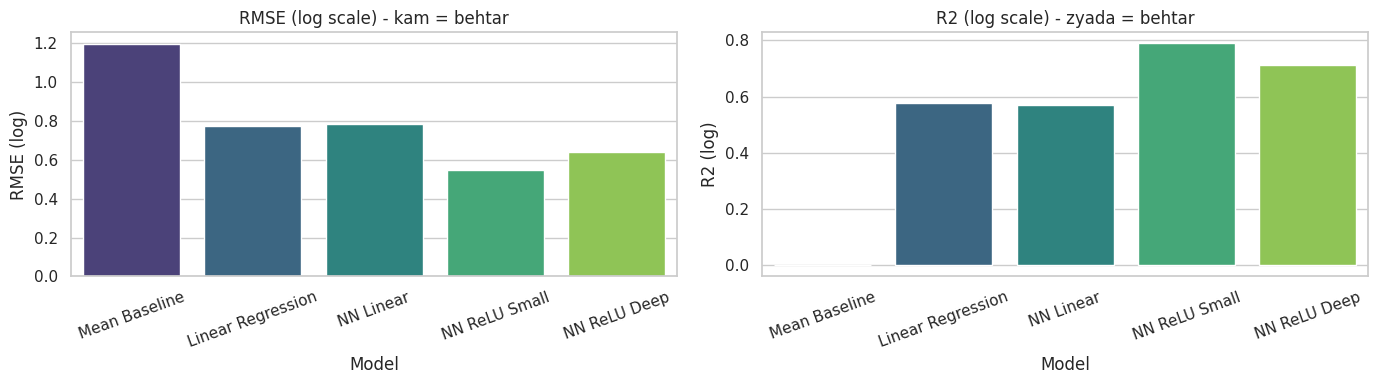

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))                           # 2 charts ek row mein
sns.barplot(x=res.index, y=res["RMSE (log)"], ax=ax[0],                 # pehla bar chart: RMSE (log)
            palette="viridis", hue=res.index, legend=False)             # rang viridis, alag legend nahi
ax[0].set_title("RMSE (log scale) - kam = behtar")                      # title: kam error = achha
ax[0].tick_params(axis="x", rotation=20)                                # x ke naam thoda tirchhe karo
sns.barplot(x=res.index, y=res["R2 (log)"], ax=ax[1],                   # doosra bar chart: R2 (log)
            palette="viridis", hue=res.index, legend=False)             # wahi rang aur setting
ax[1].set_title("R2 (log scale) - zyada = behtar")                      # title: zyada R2 = achha
ax[1].tick_params(axis="x", rotation=20)                                # x ke naam tirchhe
plt.tight_layout()                                                      # charts adjust karo
plt.show()                                                              # charts dikhao

## 10. Best model ke predictions

In [ ]:
best_name = res.loc[res.index .str.startswith('NN'), 'RMSE (log)'].idxmin()
best_model = models[best_name]
pred =np.clip(best_model.predict(X_test, verbose=0).ravel(), 0, None)
print('Best Neural Network:', best_name)

Best Neural Network: NN ReLU Small


In [ ]:
best_name = res.loc[res.index.str.startswith("NN"), "RMSE (log)"].idxmin()   # NN models mein se sabse kam RMSE wale ka naam
best_model = models[best_name]                                               # us best model ko nikalo
pred = np.clip(best_model.predict(X_test, verbose=0).ravel(), 0, None)       # test par predict karo, 1D karo, 0 se neeche na jaane do
print("Best Neural Network:", best_name)                                     # best model ka naam dikhao

Best Neural Network: NN ReLU Small


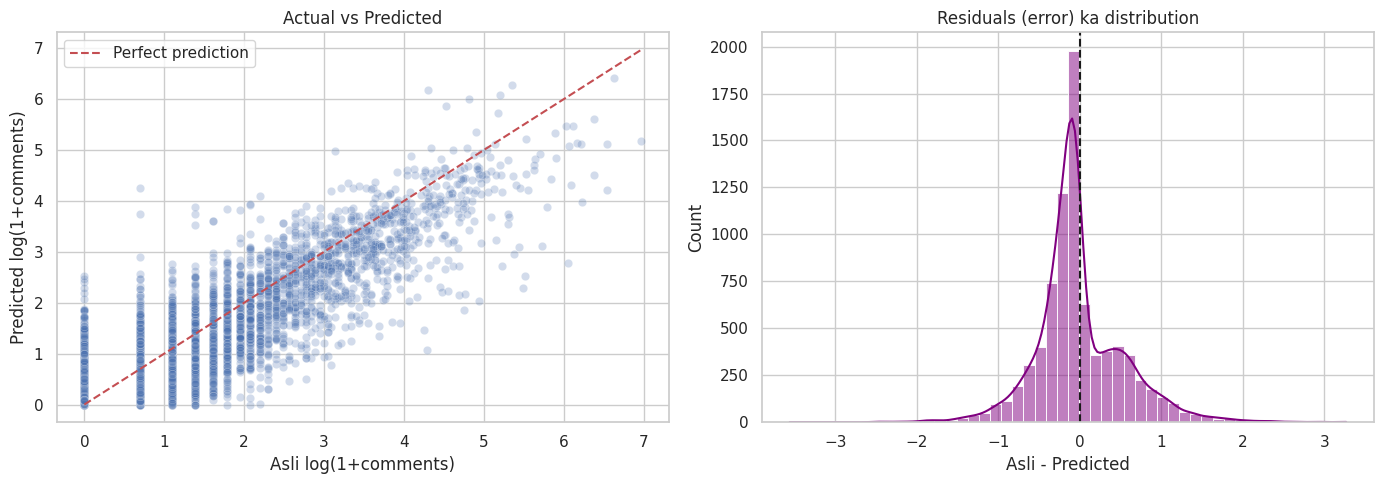

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))                                # 2 charts ek row mein
sns.scatterplot(x=y_test, y=pred, alpha=0.25, ax=ax[0])                      # asli vs predicted ka scatter plot (halka transparent)
lim = [0, max(y_test.max(), pred.max())]                                     # perfect line ke liye axis ki range
ax[0].plot(lim, lim, "r--", label="Perfect prediction")                      # laal dotted line: jahan predicted = asli
ax[0].set_xlabel("Asli log(1+comments)")                                     # x-axis ka naam
ax[0].set_ylabel("Predicted log(1+comments)")                                # y-axis ka naam
ax[0].set_title("Actual vs Predicted")                                       # chart ka title
ax[0].legend()                                                               # label dikhao

sns.histplot(y_test - pred, bins=50, kde=True, ax=ax[1], color="purple")     # residual (asli - predicted) ka histogram
ax[1].axvline(0, color="k", ls="--")                                         # 0 par kaali dotted line (zero error)
ax[1].set_title("Residuals (error) ka distribution")                         # chart ka title
ax[1].set_xlabel("Asli - Predicted")                                         # x-axis ka naam
plt.tight_layout()                                                           # charts adjust karo
plt.show()                                                                   # charts dikhao

In [ ]:
sample = pd.DataFrame({"Asli comments": np.expm1(y_test[:10]).round(0),      # pehle 10 test posts ke asli comments
                       "Predicted comments": np.expm1(pred[:10]).round(1)})  # unke liye model ka andaza (asli scale par)
sample                                                                       # table dikhao

,Asli comments,Predicted comments
0,0.0,2.400000
1,1.0,0.100000
2,0.0,0.900000
3,38.0,22.700001
4,0.0,0.200000
5,0.0,0.300000
6,19.0,17.299999
7,2.0,1.200000
8,18.0,15.700000
9,0.0,0.100000


## 11. Final Conclusion

In [29]:
lin_r2 = res.loc["Linear Regression", "R2 (log)"]                            # Linear Regression ka R2
best_r2 = res.loc[best_name, "R2 (log)"]                                     # best NN ka R2
lin_rmse = res.loc["Linear Regression", "RMSE (log)"]                        # Linear Regression ka RMSE
best_rmse = res.loc[best_name, "RMSE (log)"]                                 # best NN ka RMSE

print("Best NN        :", best_name)                                                  # best NN ka naam
print(f"R2   (log)     : Linear {lin_r2:.3f}  ->  NN {best_r2:.3f}")                   # R2 compare karo
print(f"RMSE (log)     : Linear {lin_rmse:.3f}  ->  NN {best_rmse:.3f}")               # RMSE compare karo
print(f"MAE (comments) : Linear {res.loc['Linear Regression','MAE (comments)']:.2f}  ->  NN {res.loc[best_name,'MAE (comments)']:.2f}")   # asli scale par MAE compare karo

if best_rmse < lin_rmse:                                                               # agar NN ka error kam hai
    print(f"\nNeural network ne Linear Regression se {((lin_rmse - best_rmse) / lin_rmse * 100):.1f}% kam error diya (nonlinearity ka fayda).")   # kitna % behtar hai batao
else:                                                                                  # warna
    print("\nIs run mein Neural network, Linear Regression se behtar nahi nikla. Architecture/epochs/features badal ke dekho.")   # sujhav do

Best NN        : NN ReLU Small
R2   (log)     : Linear 0.579  ->  NN 0.789
RMSE (log)     : Linear 0.776  ->  NN 0.549
MAE (comments) : Linear 145.14  ->  NN 4.27

Neural network ne Linear Regression se 29.3% kam error diya (nonlinearity ka fayda).


### Summary
- **Dataset:** Facebook Comment Volume (Variant 1), 40,949 posts, 53 features. **Target:** comments ki sankhya.
- **Problem type:** Regression (output = 1 number).
- **Preprocessing:** duplicates + constant column hataye, `log1p` se target ka skew kam kiya, StandardScaler (train par fit), 80-20 split.
- **Models:** Mean baseline, Linear Regression, aur 3 Neural Networks (Linear / ReLU Small / ReLU Deep), Adam + MSE + EarlyStopping.
- **Metrics:** RMSE, MAE, R2. `(log)` wale scores model ki asli quality dikhate hain. `(comments)` wale scores viral posts (outliers) ki wajah se bade dikhte hain.
- **Nonlinearity ka test:** `NN Linear` (activation nahi) vs `NN ReLU` ka farak batata hai ki hidden layers + ReLU se kitna fayda hua.

### Aage kya try kar sakte ho
1. `Features_Variant_2/3/4/5.csv` par same notebook chalao, zyada features ke saath score compare karo.
2. `Dropout` ya `l2` regularization add karo agar overfitting dikhe.
3. Hyperparameters badlo: units, learning rate, batch size.
4. Random Forest / XGBoost ka baseline lagao (tabular data par ye aksar NN se achhe hote hain).
5. Note: data ek hi page ke posts line se rakhta hai, aur random split mein same page train aur test dono mein aa sakta hai. Zyada strict test ke liye page ke hisaab se split (GroupShuffleSplit) try karo.